In [23]:
#acces a servidor
import os
import requests
#avg_no2 --> avg
#detailed_no2 --> hores
option_db = 'avg_no2'
pollutant = requests.get('http://mappo-server.herokuapp.com/database?option='+option_db)


pollutant = str(pollutant.content)
primer_caracter = False
last_char = ''
#print(pollutant)
with open(option_db+'.csv', 'w') as f:

    if "detailed" not in option_db:
        f.write("estacio,data,contaminant,unitats,latitud,longitud,valor,\n")
    else:
        f.write("estacio,data,contaminant,unitats,latitud,longitud,quantity,\n")

    for c in pollutant:
        if c == '(':
            primer_caracter = True
            
        if (c >= '0' and c <= '9' or c >= 'A' and c <= 'Z' or c >= 'a' and c <= 'z' or c == '.' or c == '-' or c == ',' or c == ' ' or c == ':') and primer_caracter==True:
            last_char = c
            f.write(c)

        elif c == ')' and primer_caracter == True:
            f.write(',')
            last_char = c
            f.write('\n')
            primer_caracter = False

In [246]:
import numpy as np
import pandas as pd
import psycopg2
import seaborn as sns
import matplotlib.pyplot as plt
import datetime
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from datetime import date
from sklearn.preprocessing import LabelEncoder
from itertools import islice

#Dataset
dataset = pd.read_csv('/content/avg_no2.csv', sep = ',')#index_col=1
df = pd.DataFrame(dataset, columns=['estacio','data', 'contaminant', 'unitats', 'latitud', 'longitud', 'valor'])
df.fillna(method="ffill", inplace=True)
df = df.sort_values(by='data')

#Dataset to arrays
valores = df['valor']
dates = df['data']
suma = np.zeros(len(valores), float)
dates.reset_index(drop=True, inplace=True)
valores.reset_index(drop=True, inplace=True)
fecha = []
print(dates)

#Computing daily avg 
multiple = 8
ultim = 943
for i in range(len(valores)):
  if i%8 == 0 and i!=0 or i==ultim:    
    if i==ultim:
      fecha.append(dates[i-multiple+1]) 
      suma[i-multiple] = (sum(valores[(i-multiple+1):(i+1)])/multiple)
    else:
      fecha.append(dates[i-multiple])
      suma[i-multiple] = (sum(valores[(i-multiple):i])/multiple)

avg = suma[suma!=0]
#print((avg))
#print(fecha)

dfd = pd.DataFrame({'fecha': fecha, 'avg': list(avg)}, index=fecha, columns=['avg'])
print(dfd.size)




0      2022-01-01
1      2022-01-01
2      2022-01-01
3      2022-01-01
4      2022-01-01
          ...    
939    2022-04-28
940    2022-04-28
941    2022-04-28
942    2022-04-28
943    2022-04-28
Name: data, Length: 944, dtype: object
118


PROBLEMAS: 
Generamos gráfica con 800 valores, es decir, salen todas las estaciones concatenadas.--> investigar como agregar feature de latitud/longitud o estacion o hacer un avg de todas las estaciones
Al hacer la gráfica no podemos poner la fecha en el eje 'x'

#Tasks:
#Hay que generar una predicción para 3 df diferentes. 
#Generar una ponderación para poder predecir según acciones del usuario.

In [ ]:
#DE MOMENTO NO SE USA
#Para horas seleccionar este
#Detailed 7 dies
import numpy as np
import pandas as pd
import psycopg2
import seaborn as sns
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from datetime import date

dataset = pd.read_csv('/content/detailed_no2.csv', sep = ',', index_col=1)
df_detailed= pd.DataFrame(dataset, columns=['estacio', 'contaminant', 'unitats', 'latitud', 'longitud', 'quantity'])
df_detailed.tail()

/usr/local/lib/python3.7/dist-packages/psycopg2/__init__.py:144: UserWarning: The psycopg2 wheel package will be renamed from release 2.8; in order to keep installing from binary please use "pip install psycopg2-binary" instead. For details see: <http://initd.org/psycopg/docs/install.html#binary-install-from-pypi>.
  """)


,estacio,contaminant,unitats,latitud,longitud,quantity
data,,,,,,
2022-04-22 20:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,32.0
2022-04-22 21:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,30.0
2022-04-22 22:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,37.0
2022-04-22 23:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,43.0
2022-04-23 00:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,34.0


In [52]:
#PERSISTENCE MODEL
# convert an array of values into a dataset matrix
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	n_vars = 1 if type(data) is list else data.shape[1]
	df = pd.DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(df.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(df.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = pd.concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg

  
# transform series into train and test sets for supervised learning
def prepare_data(raw_values, n_test, n_lag, n_seq):
	# extract raw values
	#raw_values = series.values
	raw_values = raw_values.reshape(len(raw_values), 1)
	# transform into supervised learning problem X, y
	supervised = series_to_supervised(raw_values, n_lag, n_seq)
	supervised_values = supervised.values
	# split into train and test sets
	train, test = supervised_values[0:-n_test], supervised_values[-n_test:]
	#	train, test = supervised_values[0:-n_test], supervised_values[-n_test:]
	return train, test

  # make a persistence forecast
def persistence(last_ob, n_seq):
	return [last_ob for i in range(n_seq)]


# evaluate the persistence model
def make_forecasts(train, test, n_lag, n_seq):
	forecasts = list()
	for i in range(len(test)):
		X, y = test[i, 0:n_lag], test[i, n_lag:]
		# make forecast
		forecast = persistence(X[-1], n_seq) #X[-1]
		# store the forecast
		forecasts.append(forecast)
	return forecasts

# evaluate the RMSE for each forecast time step
def evaluate_forecasts(test, forecasts, n_lag, n_seq):
	for i in range(n_seq):
		actual = test[:,(n_lag+i)]
		predicted = [forecast[i] for forecast in forecasts]
		rmse = math.sqrt(mean_squared_error(actual, predicted))
		print('t+%d RMSE: %f' % ((i+1), rmse))
 
# plot the forecasts in the context of the original dataset
def plot_forecasts(values, forecasts, n_test):
	# plot the entire dataset in blue
	plt.plot(values)
	# plot the forecasts in red
	for i in range(len(forecasts)):
		off_s = len(values) - n_test + i - 1
		off_e = off_s + len(forecasts[i]) + 1 
		xaxis = [x for x in range(off_s, off_e)] 
		yaxis = [values[off_s]] + forecasts[i]
		plt.plot(xaxis, yaxis, color='red')
	# show the plot
	plt.show()

Train: (112, 2), Test: (5, 2)
t+1 RMSE: 0.281948


/usr/local/lib/python3.7/dist-packages/numpy/core/shape_base.py:65: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  ary = asanyarray(ary)


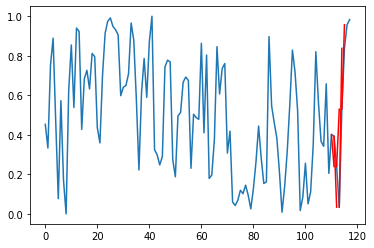

In [55]:
import math
#df.drop('contaminant', 1, inplace=True)
#df.drop('unitats', 1, inplace=True)
#df.drop('estacio', 1, inplace=True)
#df.drop('latitud', 1, inplace=True)
#df.drop('longitud', 1, inplace=True)

values = dfd.values
# integer encode direction
encoder = LabelEncoder()
values[:,0] = encoder.fit_transform(values[:,0])

#print(values)
# ensure all data is float
values = values.astype('float32')

#normalize dataset
scaler = MinMaxScaler(feature_range=(0,1))
#scaled = scaler.fit_transform(df['quantity'].array.reshape(-1,1)) #reshape(-1,1) porque sólo es una feature
scaled = scaler.fit_transform(values)

# frame as supervised learning

# configure
n_lag = 1
n_seq = 1
n_test = 5
# prepare data
train, test = prepare_data(scaled, n_test, n_lag, n_seq)
print('Train: %s, Test: %s' % (train.shape, test.shape))
 
# make forecasts
forecasts = make_forecasts(train, test, n_lag, n_seq)
# evaluate forecasts
evaluate_forecasts(test, forecasts, n_lag, n_seq)
# plot forecasts
plot_forecasts(scaled, forecasts, n_test+2)

In [247]:
#MULTISTEP FORECAST
from pandas import DataFrame
from pandas import Series
from pandas import concat
from pandas import read_csv
from pandas import datetime
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from math import sqrt
from matplotlib import pyplot
from numpy import array
 
# convert time series into supervised learning problem
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	n_vars = 1 if type(data) is list else data.shape[1]
	df = DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(df.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(df.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg
 
# create a differenced series
def difference(dataset, interval=1):
	diff = list()
	for i in range(interval, len(dataset)):
		value = dataset[i] - dataset[i - interval]
		diff.append(value)
	return Series(diff)
 
def prepare_data(series, n_test, n_lag, n_seq):
	# extract raw values
	raw_values = series.values
	# transform data to be stationary
	diff_series = difference(raw_values, 1)
	diff_values = diff_series.values
	diff_values = diff_values.reshape(len(diff_values), 1)
	# rescale values to -1, 1
	scaler = MinMaxScaler(feature_range=(0, 1)) #antes -1,1
	scaled_values = scaler.fit_transform(diff_values)
	scaled_values = scaled_values.reshape(len(scaled_values), 1)
	# transform into supervised learning problem X, y
	supervised = series_to_supervised(scaled_values, n_lag, n_seq)
	supervised_values = supervised.values
	# split into train and test sets
	train, test = supervised_values[0:-n_test], supervised_values[-n_test:]
	return scaler, train, test, diff_series

# fit an LSTM network to training data
def fit_lstm(train, n_lag, n_seq, n_batch, nb_epoch, n_neurons):
	look_back = 1
	# reshape training into [samples, timesteps, features]
	X, y = train[:, 0:n_lag], train[:, n_lag:]
	X = X.reshape((-1,1))
  #X = X.reshape(X.shape[0], 1, X.shape[1])
	# design network
	model = Sequential()
	model.add(LSTM(n_neurons, input_shape=(look_back, 1))) #model.add(LSTM(n_neurons, batch_input_shape=(n_batch, X.shape[1], X.shape[2]), stateful=True))
	model.add(Dense(y.shape[1]))
	model.compile(loss='mean_squared_error', optimizer='adam')
	# fit network
	for i in range(nb_epoch):
		model.fit(X, y, epochs=1, batch_size=n_batch, verbose=0, shuffle=False)
		model.reset_states()
	return model


# make one forecast with an LSTM,
def forecast_lstm(model, X, n_batch):
	# reshape input pattern to [samples, timesteps, features]
	X = X.reshape(1, 1, len(X))
	# make forecast
	forecast = model.predict(X, batch_size=n_batch)
	# convert to array
	return [x for x in forecast[0, :]]
 
# evaluate the persistence model
def make_forecasts(model, n_batch, train, test, n_lag, n_seq):
	forecasts = list()
	for i in range(len(test)):
		X, y = test[i, 0:n_lag], test[i, n_lag:]
		# make forecast
		forecast = forecast_lstm(model, X, n_batch)
		# store the forecast
		forecasts.append(forecast)
	return forecasts
 
# invert differenced forecast
def inverse_difference(last_ob, forecast):
	# invert first forecast
	inverted = list()
	inverted.append(forecast[0] + last_ob)
	# propagate difference forecast using inverted first value
	for i in range(1, len(forecast)):
		inverted.append(forecast[i] + inverted[i-1])
	return inverted

# inverse data transform on forecasts
def inverse_transform(series, forecasts, scaler, n_test):
	inverted = list()
	for i in range(len(forecasts)):
		# create array from forecast
		forecast = array(forecasts[i])
		forecast = forecast.reshape(1, len(forecast))
		# invert scaling
		inv_scale = scaler.inverse_transform(forecast)
		inv_scale = inv_scale[0, :]
		# invert differencing
		index = len(series) - n_test + i - 1
		last_ob = series.values[index]
		inv_diff = inverse_difference(last_ob, inv_scale)
		# store
		inverted.append(inv_diff)
	return inverted
 
# evaluate the RMSE for each forecast time step
def evaluate_forecasts(test, forecasts, n_lag, n_seq):
	for i in range(n_seq):
		actual = [row[i] for row in test]
		predicted = [forecast[i] for forecast in forecasts]
		rmse = sqrt(mean_squared_error(actual, predicted))
		print('t+%d RMSE: %f' % ((i+1), rmse))
 
# plot the forecasts in the context of the original dataset
def plot_forecasts(series, forecasts, n_test):
	# plot the entire dataset in blue
	pyplot.plot(series.values)
	# plot the forecasts in red
	for i in range(len(forecasts)):
		off_s = len(series) - n_test + i - 1
		off_e = off_s + len(forecasts[i]) + 1
		xaxis = [x for x in range(off_s, off_e)]
		yaxis = [series.values[off_s]] + forecasts[i]
		pyplot.plot(xaxis, yaxis, color='red')
	# show the plot
	pyplot.show()

In [248]:
from keras.backend import batch_normalization
n_lag = 1
n_seq = 1
n_test = 18
n_epochs = 50 #error muy grande con 200
n_batch = 1 #idealment 512, 
n_neurons = 10
# prepare data
scaler, train, test, diff_series = prepare_data(dfd, n_test, n_lag, n_seq)
# fit model
model = fit_lstm(train, n_lag, n_seq, n_batch, n_epochs, n_neurons)
# make forecasts
forecasts = make_forecasts(model, n_batch, train, test, n_lag, n_seq)
# inverse transform forecasts and test
forecasts = inverse_transform(dfd, forecasts, scaler, n_test+2)
actual = [row[n_lag:] for row in test]
actual = inverse_transform(dfd, actual, scaler, n_test+2)
# evaluate forecasts
evaluate_forecasts(actual, forecasts, n_lag, n_seq)

t+1 RMSE: 9.860346


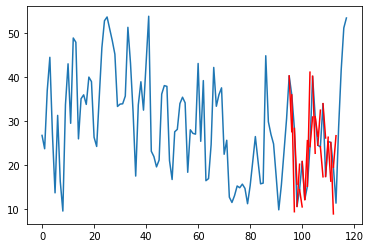

In [249]:
# plot forecasts
plot_forecasts(dfd, forecasts, n_test+4)

In [250]:
close_data = dfd.values.reshape((-1))
#close_data = close_data.reshape((-1))

look_back = 1 #1

fechas = pd.to_datetime(fecha)
# inverse data transform on forecasts
def inverse_transform_pred(series, forecasts, scaler, n_test):
	inverted = list()
	for i in range(forecasts.size):
		# create array from forecast
		forecast = array(forecasts[i])
		forecast = forecast.reshape(1, forecast.size)
		# invert scaling
		inv_scale = scaler.inverse_transform(forecast)
		inv_scale = inv_scale[0, :]
		# invert differencing
		index = len(series) - n_test + i - 1
		last_ob = series.values[index]
		inv_diff = inverse_difference(last_ob, inv_scale)
		# store
		inverted.append(inv_diff)
	return inverted
def predict(num_prediction, model):
    prediction_list = close_data[-look_back:]

    for _ in range(num_prediction):
        x = prediction_list[-look_back:]
        x = x.reshape((1, look_back, 1))
        out = model.predict(x)[0][0]
        prediction_list = np.append(prediction_list, out)
    prediction_list = prediction_list[look_back-1:]
      
    return prediction_list

def predict_dates(num_prediction):
    last_date = fechas.values[-1]
    prediction_dates = pd.date_range(last_date, periods=num_prediction+1).strftime('%Y-%m-%d').tolist()
    #prediction_dates = pd.to_datetime(prediction_dates)
    return prediction_dates

num_prediction = 30
forecast = predict(num_prediction, model)
# inverse transform forecasts and test
forecasts = inverse_transform_pred(dfd, forecast, scaler, num_prediction+2)
forecast_dates = predict_dates(num_prediction)

forecasts = np.array(forecasts)
forecasts_dates = np.array(forecast_dates)
forecasts = forecasts.reshape(-1)
forecasts = np.delete(forecasts, [0,1])
forecasts_dates = np.delete(forecasts_dates, [0,1])
forecasts_dates = pd.to_datetime(forecasts_dates)


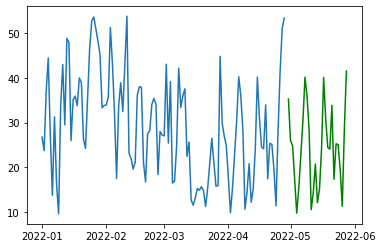

In [251]:
#Representación forecast
pyplot.plot(fechas, dfd.values)
pyplot.plot(forecasts_dates, forecasts, color='green')
# show the plot
pyplot.show()

In [ ]:
trace1 = go.Scatter(
    x = fechas[0:-n_test],
    y = train,
    mode = 'lines',
    name = 'Data'
)
trace2 = go.Scatter(
    x = date_test,
    y = prediction,
    mode = 'lines',
    name = 'Prediction'
)
trace3 = go.Scatter(
    x = date_test,
    y = close_test,
    mode='lines',
    name = 'Ground Truth'
)
layout = go.Layout(
    title = "Google Stock",
    xaxis = {'title' : "Date"},
    yaxis = {'title' : "Close"}
)
fig = go.Figure(data=[trace1, trace2, trace3], layout=layout)
fig.show()

In [ ]:

#Código original forecast

reframed = series_to_supervised(scaled, n_hours, 3) #reframed = series_to_supervised(scaled, n_hours, 1)

# drop columns we don't want to predict
#reframed.drop(reframed.columns[[9,10,11,12,13,14,15]], axis=1, inplace=True)
reframed.drop(reframed.columns[[3,4]], axis=1, inplace=True)
reframed.tail()


# split into train and test sets
values = reframed.values
n_train_hours = 52 * 24 #REVISAR VALOR
train = values[:n_train_hours, :]
test = values[n_train_hours:, :]
# split into input and outputs

n_obs = n_hours * n_features
train_X, train_y = train[:, :n_obs], train[:, -n_features]
test_X, test_y = test[:, :n_obs], test[:, -n_features]
print(train_X.shape, len(train_X), train_y.shape)
#Abans sense multiple time lagstamps
#train_X, train_y = train[:, :-1], train[:, -1]
#test_X, test_y = test[:, :-1], test[:, -1]

# reshape input to be 3D [samples, timesteps, features]
#train_X = train_X.reshape((train_X.shape[0], 1, train_X.shape[1]))
#test_X = test_X.reshape((test_X.shape[0], 1, test_X.shape[1]))
#print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)

# reshape input to be 3D [samples, timesteps, features]
train_X = train_X.reshape((train_X.shape[0], n_hours, n_features))
test_X = test_X.reshape((test_X.shape[0], n_hours, n_features))

In [ ]:
# design network
model = Sequential()
model.add(LSTM(50, input_shape=(train_X.shape[1], train_X.shape[2])))
model.add(Dense(1))
model.compile(loss='mae', optimizer='adam')
# fit network
history = model.fit(train_X, train_y, epochs=50, batch_size=72, validation_data=(test_X, test_y), verbose=2, shuffle=False)
print(history)
# plot history
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

In [ ]:
from math import sqrt
from numpy import concatenate
#WITH Multiple Lag Timesteps
# make a prediction
yhat = model.predict(test_X)
test_X = test_X.reshape((test_X.shape[0], n_hours*n_features))
# invert scaling for forecast
inv_yhat = concatenate((yhat, test_X[:, -2:]), axis=1)
inv_yhat = scaler.inverse_transform(inv_yhat)
inv_yhat = inv_yhat[:,0]
# invert scaling for actual
test_y = test_y.reshape((len(test_y), 1))
inv_y = concatenate((test_y, test_X[:, -2:]), axis=1)
inv_y = scaler.inverse_transform(inv_y)
inv_y = inv_y[:,0]
# calculate RMSE
rmse = sqrt(mean_squared_error(inv_y, inv_yhat))
print('Test RMSE: %.3f' % rmse)